if tow output labels then sparse_catagorical_crossentropy , else if one output label then binary cross entropy or catagorical crossentropy
-- sparse catagorical we use when out output labels are not one hot encoded 

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random

In [106]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense , Flatten , Conv2D , MaxPool2D
from tensorflow.keras.callbacks import EarlyStopping

## load dataset 


In [16]:
X_train = np.loadtxt('e:\DataSets\Animal Dataset\input.csv',delimiter=',')
y_train = np.loadtxt('e:\DataSets\Animal Dataset\labels.csv',delimiter=',')
X_test = np.loadtxt('e:\DataSets\Animal Dataset\input_test.csv',delimiter=',')
y_test = np.loadtxt('e:\DataSets\Animal Dataset\labels_test.csv',delimiter=',')

<>:1: SyntaxWarning: invalid escape sequence '\D'
<>:2: SyntaxWarning: invalid escape sequence '\D'
<>:3: SyntaxWarning: invalid escape sequence '\D'
<>:4: SyntaxWarning: invalid escape sequence '\D'
<>:1: SyntaxWarning: invalid escape sequence '\D'
<>:2: SyntaxWarning: invalid escape sequence '\D'
<>:3: SyntaxWarning: invalid escape sequence '\D'
<>:4: SyntaxWarning: invalid escape sequence '\D'
C:\Users\Admin\AppData\Local\Temp\ipykernel_16028\3459683417.py:1: SyntaxWarning: invalid escape sequence '\D'
  X_train = np.loadtxt('e:\DataSets\Animal Dataset\input.csv',delimiter=',')
C:\Users\Admin\AppData\Local\Temp\ipykernel_16028\3459683417.py:2: SyntaxWarning: invalid escape sequence '\D'
  y_train = np.loadtxt('e:\DataSets\Animal Dataset\labels.csv',delimiter=',')
C:\Users\Admin\AppData\Local\Temp\ipykernel_16028\3459683417.py:3: SyntaxWarning: invalid escape sequence '\D'
  X_test = np.loadtxt('e:\DataSets\Animal Dataset\input_test.csv',delimiter=',')
C:\Users\Admin\AppData\Local\Te

In [31]:
X_train = X_train.reshape(len(X_train),100,100,3) #(2000,100,100,3)
y_train = y_train.reshape(len(Y_train), 1)

X_test = X_test.reshape(len(X_test), 100, 100, 3)
Y_test = Y_test.reshape(len(Y_test), 1)

X_train = X_train/255.0
X_test = X_test/255.0

In [29]:
y_train.shape

(2000, 1)

In [30]:
X_train.shape

(2000, 100, 100, 3)

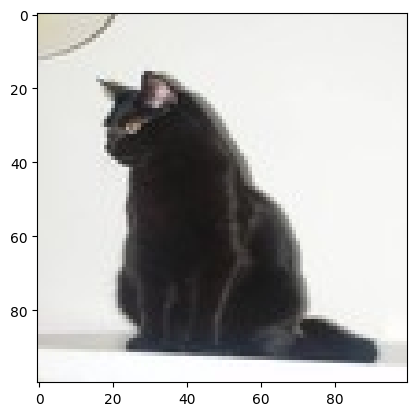

In [42]:
idx = random.randint(0,len(X_train))
plt.imshow(X_train[idx])
plt.show()

# training neural network

In [64]:
model = Sequential()
model.add(Flatten(input_shape=(100,100,3)))  #converts multidimensional data to 1D
model.add(Dense(128,activation='relu'))
model.add(Dense(128,activation='relu'))
model.add(Dense(2, activation='softmax'))


f:\desktop\ML\.venv\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [65]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)             │ (None, 30000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │     3,840,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,856,898 (14.71 MB)

 Trainable params: 3,856,898 (14.71 MB)

 Non-trainable params: 0 (0.00 B)

In [66]:
model.compile(loss='sparse_categorical_crossentropy',optimizer='Adam',metrics=['accuracy'])  # categorical_crossentropy because my y labels are already onehot encoded 

In [67]:
history=model.fit(X_train,y_train,epochs=20,validation_split=0.2)

Epoch 1/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - accuracy: 0.5506 - loss: 2.1926 - val_accuracy: 0.9700 - val_loss: 0.3127
Epoch 2/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 70ms/step - accuracy: 0.5575 - loss: 0.9300 - val_accuracy: 0.0025 - val_loss: 2.4575
Epoch 3/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 74ms/step - accuracy: 0.5987 - loss: 0.7782 - val_accuracy: 0.9975 - val_loss: 0.2695
Epoch 4/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 74ms/step - accuracy: 0.6081 - loss: 0.7118 - val_accuracy: 0.0000e+00 - val_loss: 2.8479
Epoch 5/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 70ms/step - accuracy: 0.6000 - loss: 0.7646 - val_accuracy: 0.3425 - val_loss: 0.8469
Epoch 6/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 6s 77ms/step - accuracy: 0.6175 - loss: 0.6758 - val_accuracy: 0.8075 - val_loss: 0.5286
Epoch 7/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step - accuracy: 0.6175 - loss: 0.6957 - val_accuracy: 0.3525 - val_loss: 0.8410
Epoch 8/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 70ms/step - accuracy: 0.6506 - loss: 0.6283 - val_accuracy: 0.72

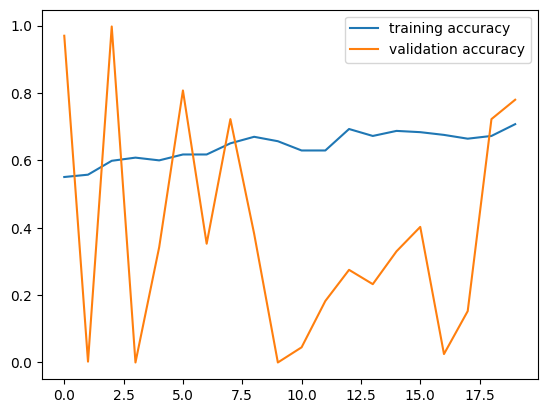

In [68]:
plt.plot(history.history['accuracy'],label="training accuracy")
plt.plot(history.history['val_accuracy'],label = 'validation accuracy')
plt.legend()
plt.show()

In [86]:
y_pred = model.predict(X_train)

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


In [87]:
y_pred = y_pred.argmax(axis=1)
y_pred

array([0, 0, 1, ..., 1, 0, 1], shape=(2000,))

In [74]:
from sklearn.metrics import accuracy_score

In [88]:
accuracy  = accuracy_score(y_train,y_pred)
accuracy

0.637

1


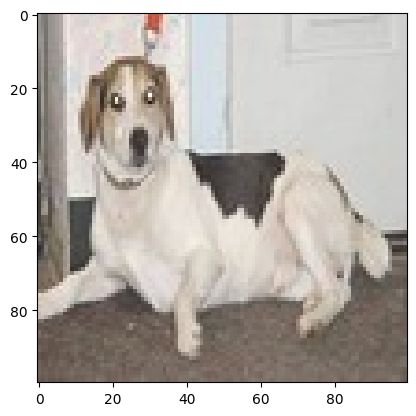

In [95]:
idx = random.randint(0,len(X_train))
plt.imshow(X_train[idx])
print(y_pred[idx])

## Traning CNN

In [102]:
model = Sequential([
    Conv2D(32,kernel_size=(3,3),padding='valid',activation='relu',input_shape=(100,100,3)),
    MaxPool2D(pool_size=(2,2),strides=2),
    Conv2D(32,kernel_size=(3,3),padding='valid',activation='relu'),
    MaxPool2D(pool_size=(2,2),strides=2),

    Flatten(), 
    Dense(74,activation='relu'),
    Dense(1,activation='sigmoid')
])

f:\desktop\ML\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [103]:
model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 98, 98, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 47, 47, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 16928)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 74)             │     1,252,746 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 1)              │            75 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,262,965 (4.82 MB)

 Trainable params: 1,262,965 (4.82 MB)

 Non-trainable params: 0 (0.00 B)

In [108]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [109]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

In [110]:
history = model.fit(X_train,y_train,epochs=20,validation_split=0.2,callbacks=[early_stop])

Epoch 1/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 21s 203ms/step - accuracy: 0.9956 - loss: 0.0199 - val_accuracy: 0.6125 - val_loss: 2.0244
Epoch 2/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 10s 193ms/step - accuracy: 0.9975 - loss: 0.0173 - val_accuracy: 0.5000 - val_loss: 2.9189
Epoch 3/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 9s 172ms/step - accuracy: 0.9937 - loss: 0.0275 - val_accuracy: 0.5900 - val_loss: 2.2765
Epoch 4/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 10s 164ms/step - accuracy: 0.9887 - loss: 0.0379 - val_accuracy: 0.6200 - val_loss: 2.1559
Epoch 5/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 9s 175ms/step - accuracy: 0.9869 - loss: 0.0392 - val_accuracy: 0.5825 - val_loss: 2.6272
